# Week 2 - Data-quality assessment of the Sephora skincare review files
**YuvaIntern - Data Science with Python Analyst Internship** | Mohammed Anas

This notebook supports Section 9 of the Week 2 report. It (1) re-checks the key data-quality facts directly from the original CSV files using lightweight columns, (2) shows the tables and figures produced by the scripts in `week2/code`, and (3) asserts that the live numbers equal the numbers quoted in the report. Nothing here modifies the raw data.

This notebook sits at the repository root. **Before running:** place the six CSV files in `data/` (see README) and run `python week2/code/00_file_checksums.py` ... `04_make_week2_figures.py` once (about 10 minutes), or let the next cell run the missing steps.

In [1]:
import glob, json, subprocess, sys
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import Image, display
pd.set_option('display.width', 150); pd.set_option('display.max_columns', 30)
ROOT = Path.cwd().parents[1] if Path.cwd().name == 'code' else Path.cwd()
W2, DATA = ROOT/'week2', ROOT/'data'
need = W2/'results'/'w2_inventory.json'
if not need.exists():
    for s in ['00_file_checksums','01_data_inventory','02_stats_and_text_profile','03_nlp_pilot','04_make_week2_figures']:
        subprocess.run([sys.executable, str(W2/'code'/f'{s}.py')], check=True)
I = json.load(open(W2/'results'/'w2_inventory.json')); S = json.load(open(W2/'results'/'w2_stats.json')); NLP = json.load(open(W2/'results'/'w2_nlp_pilot.json'))
print('results loaded; review rows in report:', f"{I['N']:,}")

results loaded; review rows in report: 1,094,411


## 1. Live spot-checks from the original files (lightweight columns only)

In [2]:
files = sorted(glob.glob(str(DATA/'*reviews_*.csv'))); prod = pd.read_csv(DATA/'product_info.csv')
cols = ['author_id','rating','is_recommended','submission_time','product_id','brand_name','price_usd','helpfulness','total_feedback_count']
df = pd.concat([pd.read_csv(f, usecols=cols, dtype={'author_id': str}, low_memory=False) for f in files], ignore_index=True)
N = len(df); df['year'] = pd.to_datetime(df.submission_time).dt.year
print(f'rows: {N:,} | products: {df.product_id.nunique():,} | brands: {df.brand_name.nunique()} | authors: {df.author_id.nunique():,}')
print('rating values:', sorted(df.rating.unique().tolist()), '| rows outside 1-5:', int((~df.rating.isin([1,2,3,4,5])).sum()))
print('date range:', df.submission_time.min(), 'to', df.submission_time.max())
print('review product_ids missing from product_info.csv:', int((~df.product_id.drop_duplicates().isin(prod.product_id)).sum()), '| catalogue ids unique:', prod.product_id.is_unique)

rows: 1,094,411 | products: 2,351 | brands: 142 | authors: 503,216
rating values: [1, 2, 3, 4, 5] | rows outside 1-5: 0
date range: 2008-08-28 to 2023-03-21
review product_ids missing from product_info.csv: 0 | catalogue ids unique: True


### 1.1 Structural missingness of `is_recommended` by year (key finding)

year,2008,2009,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023
reviews,2761.0,9709.0,13485.0,12417.0,11800.0,15621.0,18224.0,21590.0,33137.0,54592.0,97996.0,143860.0,215449.0,202012.0,192227.0,49531.0
recommendation_missing_pct,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,53.5,0.0,0.0,0.0,0.0,0.0,0.1


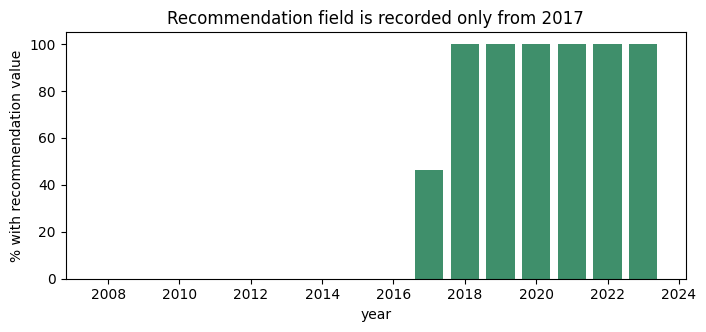

In [3]:
t = df.groupby('year').agg(reviews=('rating','size'), recommendation_missing_pct=('is_recommended', lambda s: round(100*s.isna().mean(), 1)))
display(t.T)
fig, ax = plt.subplots(figsize=(8,3.2)); ax.bar(t.index, 100-t.recommendation_missing_pct, color='#3F8F6B'); ax.set_ylabel('% with recommendation value'); ax.set_xlabel('year'); ax.set_title('Recommendation field is recorded only from 2017'); plt.show()

### 1.2 Placeholder reviewer IDs, duplicates of author-product pairs, helpfulness definition

In [4]:
nn = ~df.author_id.str.fullmatch(r'\d+')
print('placeholder author_ids:', int(nn.sum()), '| distinct:', df.author_id[nn].nunique(), '|', df.author_id[nn].str.replace(r'\d+$','',regex=True).value_counts().to_dict())
print('repeat author-product pairs:', int(df.duplicated(['author_id','product_id']).sum()))
has = df.total_feedback_count > 0
print(f'reviews with zero helpfulness votes: {100*(~has).mean():.2f}% | helpfulness missing: {100*df.helpfulness.isna().mean():.2f}%  (same reviews: {bool(((~has) == df.helpfulness.isna()).all())})')

placeholder author_ids: 64 | distinct: 21 | {'orderGen': 60, 'dummyUser': 4}


repeat author-product pairs: 5525
reviews with zero helpfulness votes: 51.31% | helpfulness missing: 51.31%  (same reviews: True)


### 1.3 Catalogue cross-check: do the review files contain the reviews the catalogue lists?

In [5]:
chk = df.groupby('product_id').rating.agg(files_reviews='size', files_mean='mean').join(prod.set_index('product_id')[['reviews','rating','primary_category']].rename(columns={'reviews':'listed_reviews','rating':'listed_rating'}))
print('share of listed review count present in files: %.2f%%' % (100*chk.files_reviews.sum()/chk.listed_reviews.sum()))
print('products equal / more / fewer than listed:', int((chk.files_reviews==chk.listed_reviews).sum()), int((chk.files_reviews>chk.listed_reviews).sum()), int((chk.files_reviews<chk.listed_reviews).sum()))
print('mean |files mean rating - catalogue rating|: %.3f' % (chk.files_mean-chk.listed_rating).abs().mean())
print('categories of reviewed products:', chk.primary_category.value_counts().to_dict())

share of listed review count present in files: 100.35%
products equal / more / fewer than listed: 1568 782 1
mean |files mean rating - catalogue rating|: 0.010
categories of reviewed products: {'Skincare': 2351}


## 2. Tables produced by the scripts

In [6]:
for f in ['t01_file_inventory','t02_missing_reviews','t04_category_coverage','t09_recommendation_by_rating_sensitivity']:
    print(f); display(pd.read_csv(W2/'tables'/f'{f}.csv'))

t01_file_inventory


,file,size_mb,rows,columns,role
0,reviews_0-250.csv,282.3,602130,19,customer reviews
1,reviews_1250-end.csv,24.2,49977,19,customer reviews
2,reviews_250-500_1.csv,100.3,206725,19,customer reviews
3,reviews_500-750_1.csv,56.3,116262,19,customer reviews
4,reviews_750-1250_1.csv,58.0,119317,19,customer reviews
5,product_info.csv,7.9,8494,27,product catalogue


t02_missing_reviews


,Unnamed: 0,missing,percent
0,helpfulness,561592,51.31
1,review_title,310654,28.39
2,hair_color,226768,20.72
3,eye_color,209628,19.15
4,skin_tone,170539,15.58
5,is_recommended,167988,15.35
6,skin_type,111557,10.19
7,review_text,1444,0.13
8,brand_name,0,0.00
9,author_id,0,0.00


t04_category_coverage


,primary_category,catalogue_products,reviewed_products,reviews,share_of_reviews_pct,share_of_catalogue_pct
0,Skincare,2420,2351,1094411,100.0,28.49
1,Makeup,2369,0,0,0.0,27.89
2,Hair,1464,0,0,0.0,17.24
3,Fragrance,1432,0,0,0.0,16.86
4,Bath & Body,405,0,0,0.0,4.77
5,Mini Size,288,0,0,0.0,3.39
6,Men,60,0,0,0.0,0.71
7,Tools & Brushes,52,0,0,0.0,0.61
8,Gifts,4,0,0,0.0,0.05


t09_recommendation_by_rating_sensitivity


,Unnamed: 0,all_recorded_rate_%,2018_plus_rate_%,2018_plus_ci95_lo_%,2018_plus_ci95_hi_%
0,1,0.77,0.77,0.70,0.85
1,2,3.67,3.62,3.45,3.80
2,3,35.66,35.68,35.33,36.04
3,4,96.57,96.55,96.46,96.64
4,5,99.86,99.86,99.85,99.87


## 3. Figures produced by the scripts

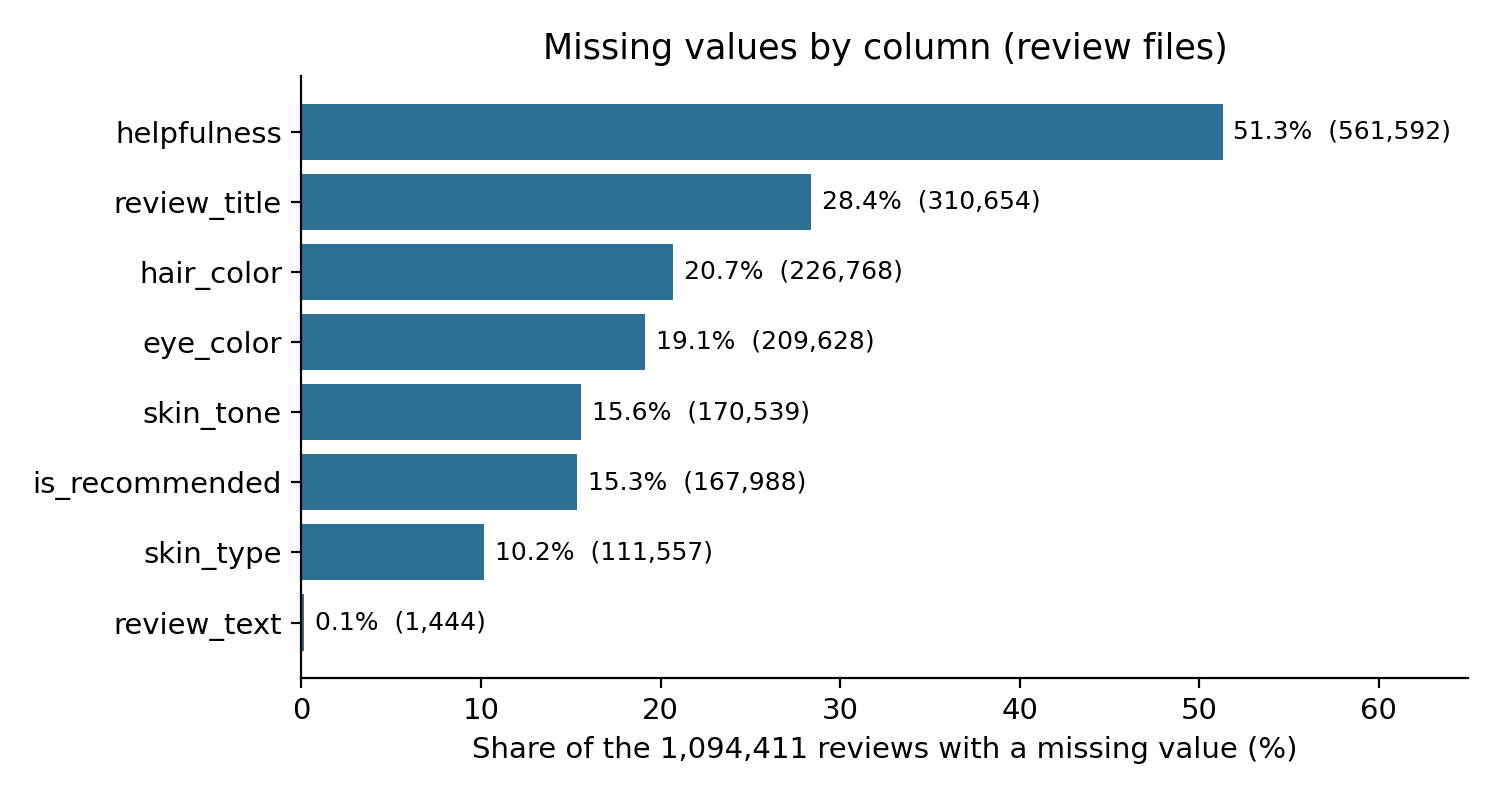

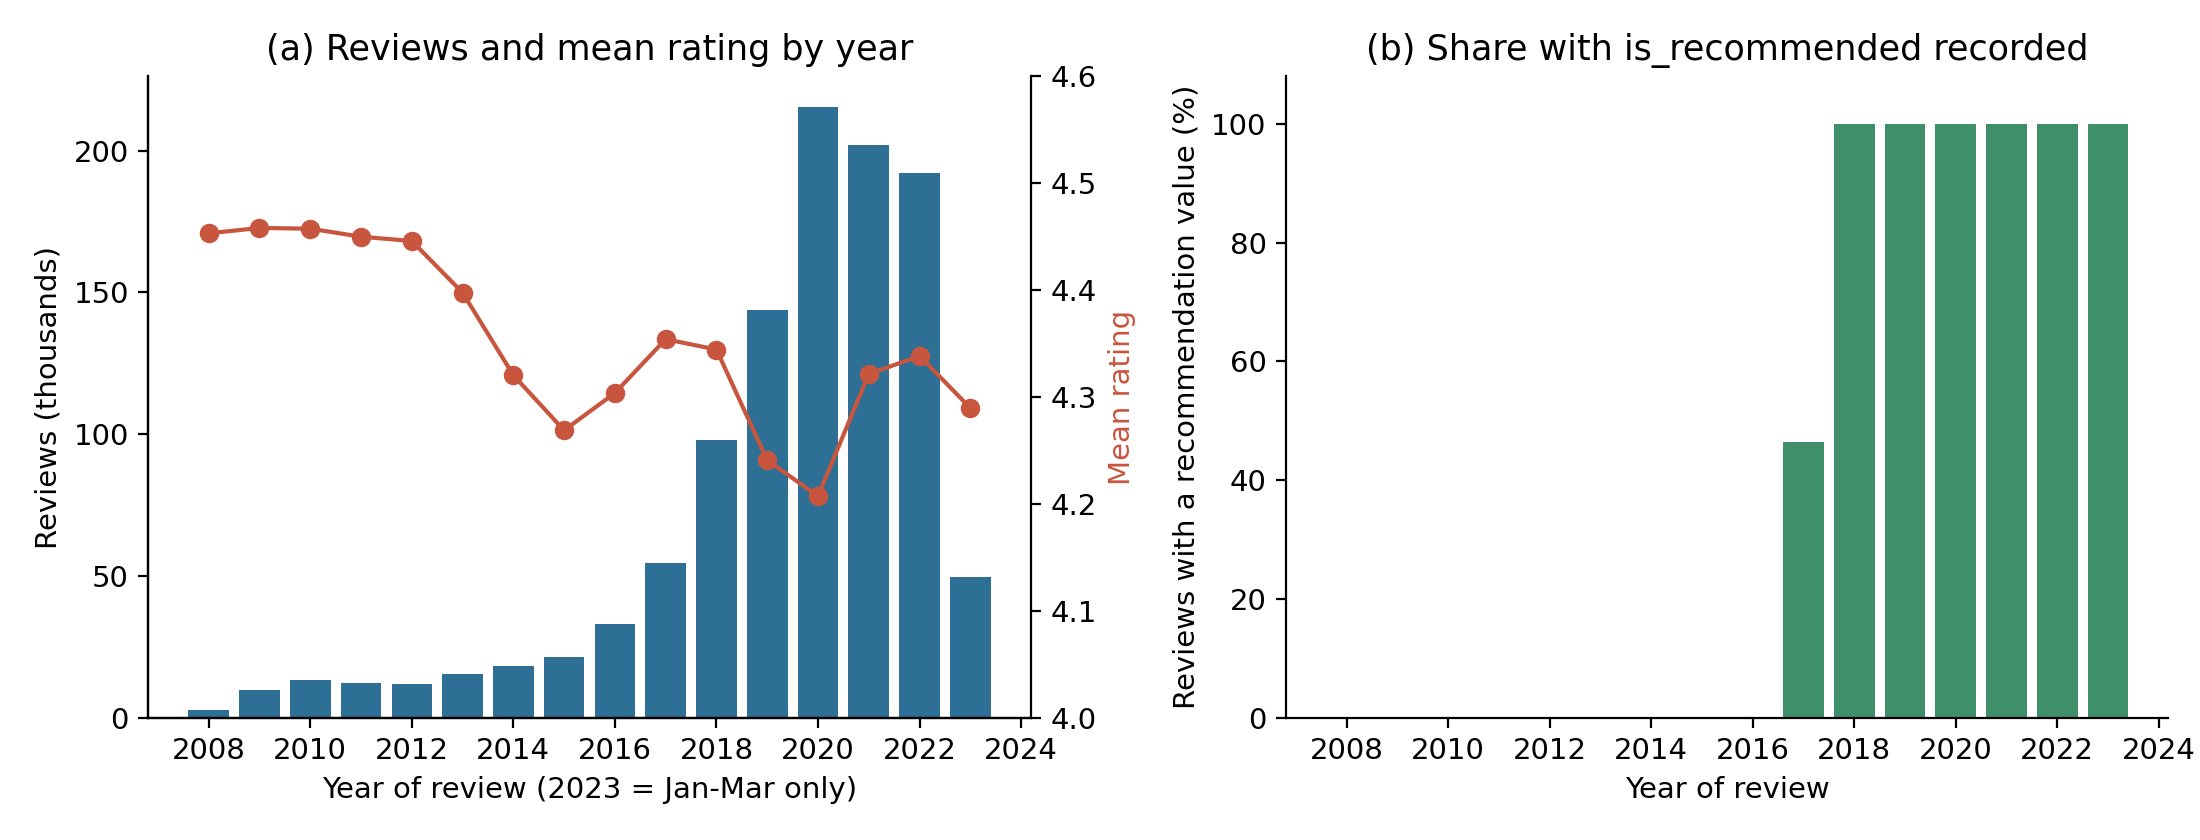

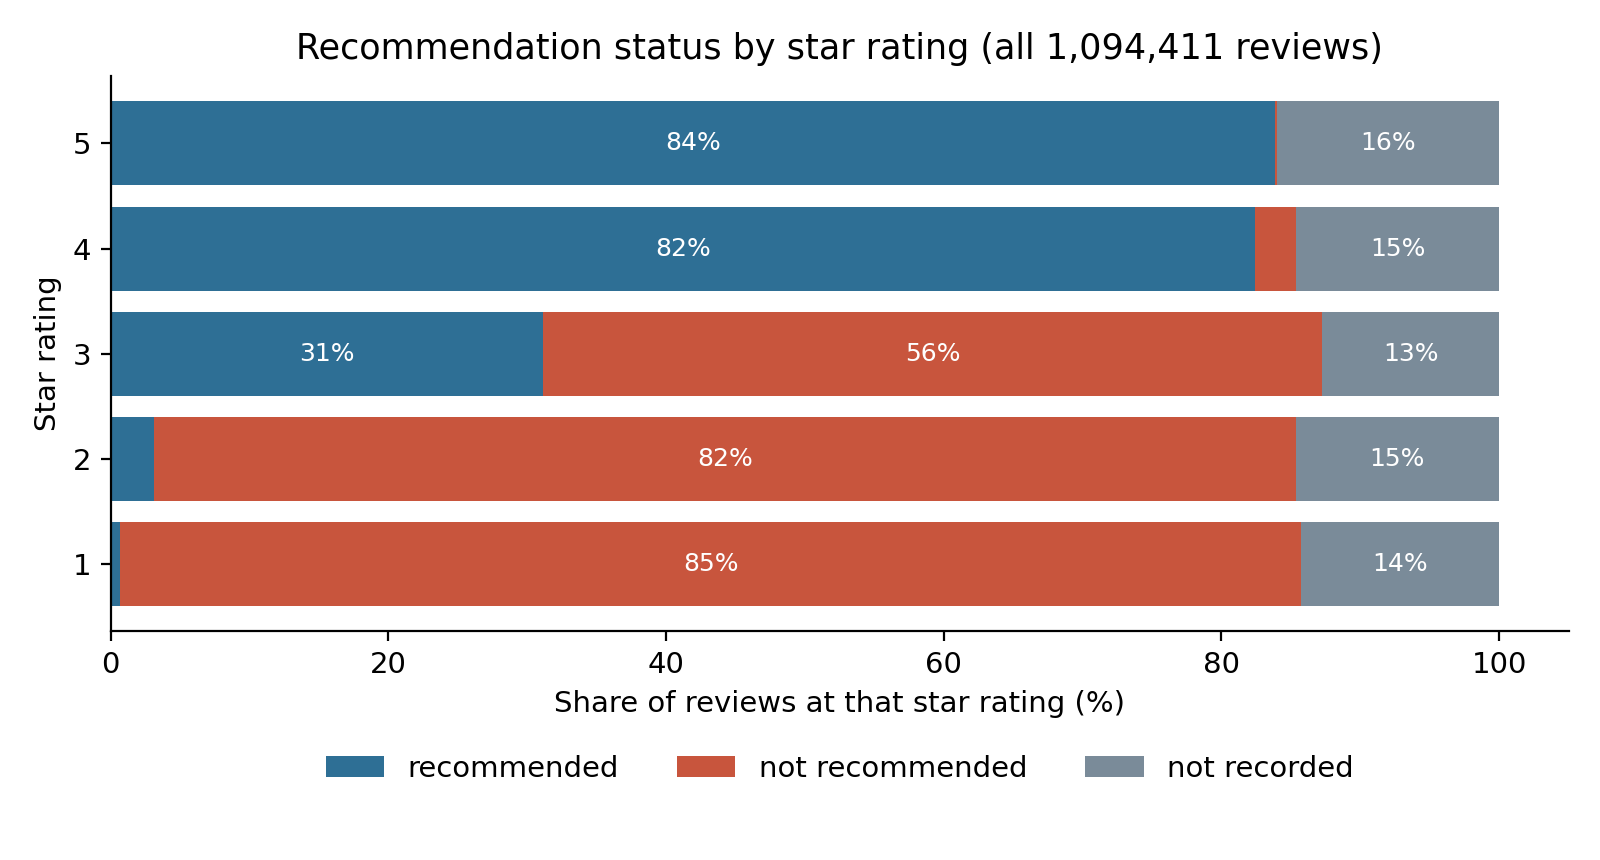

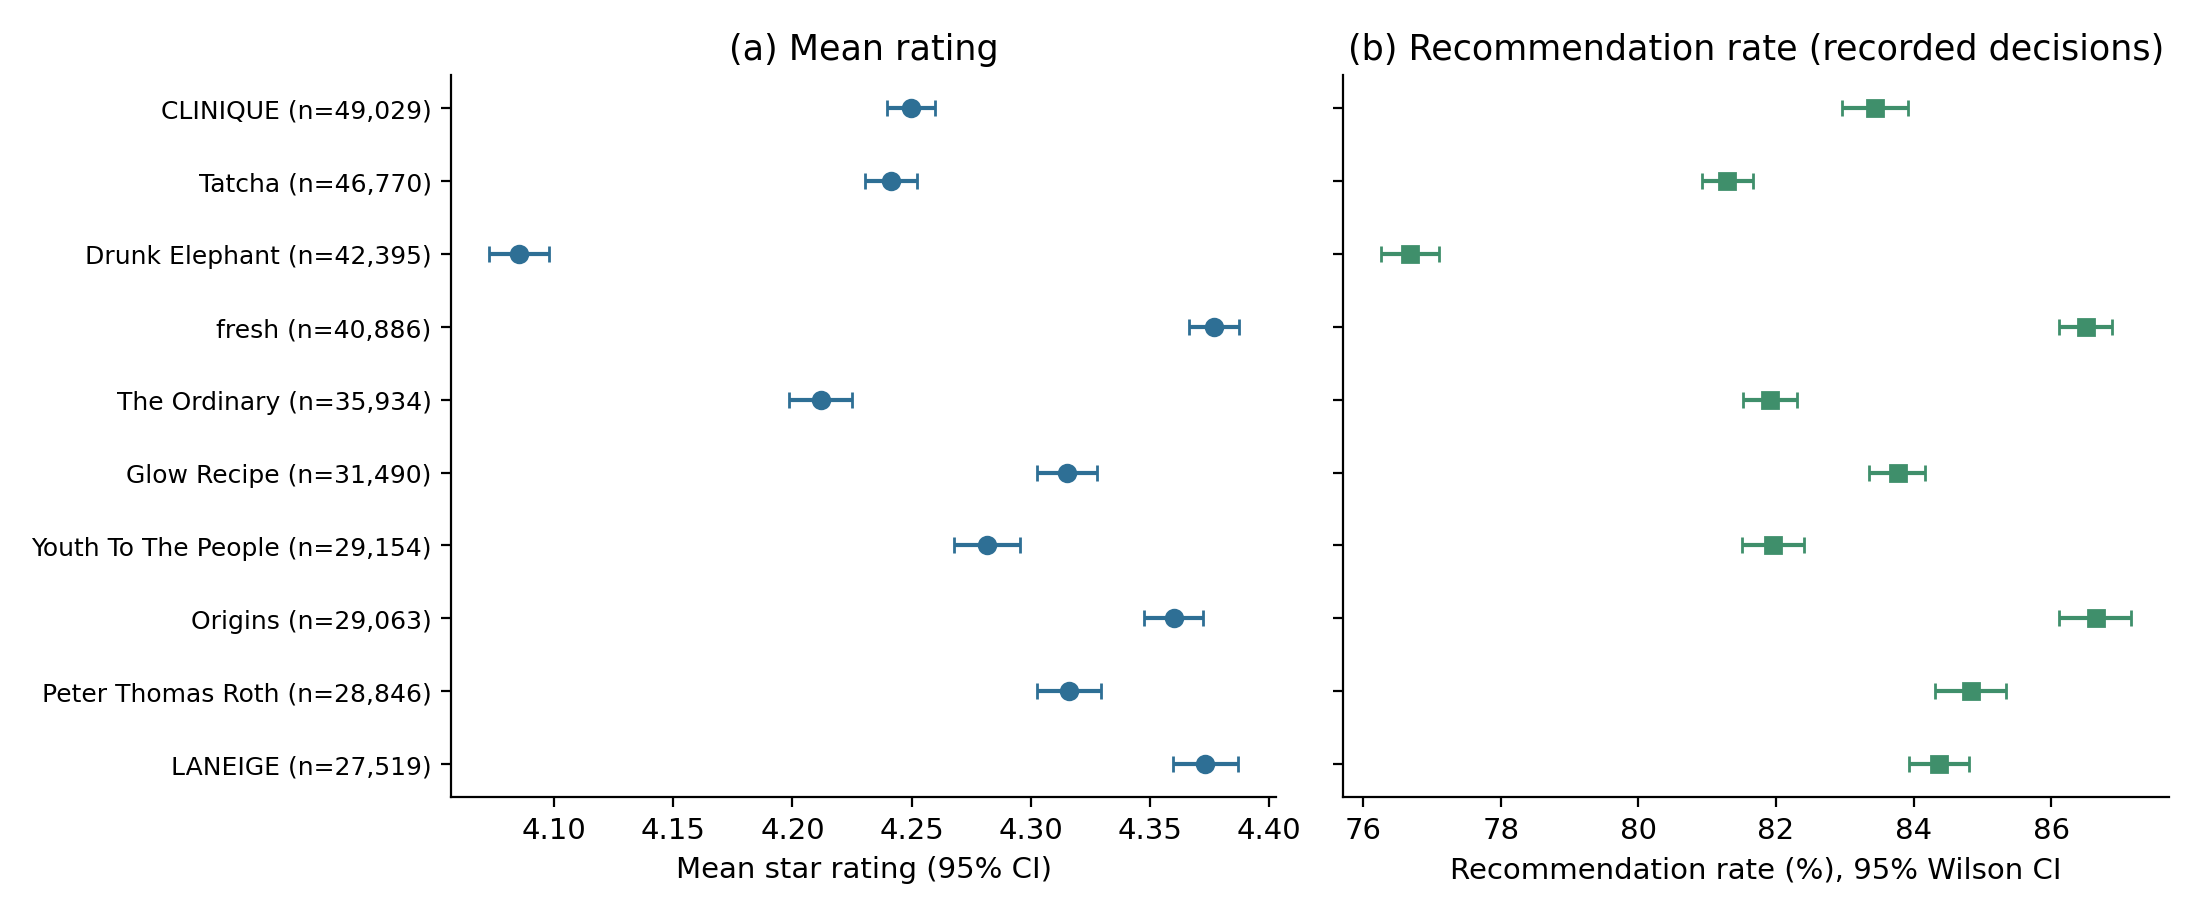

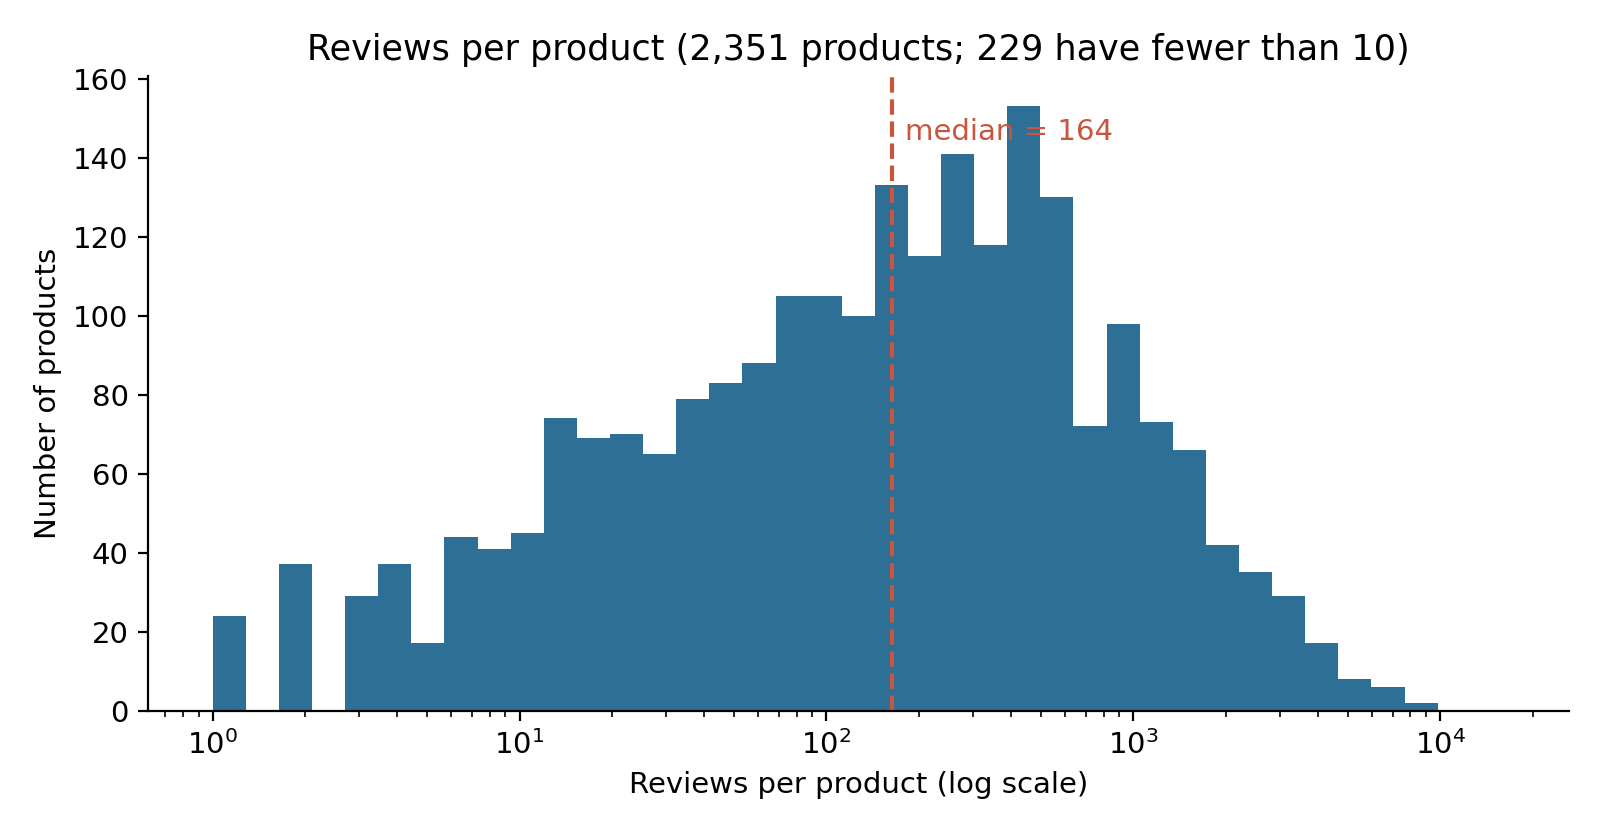

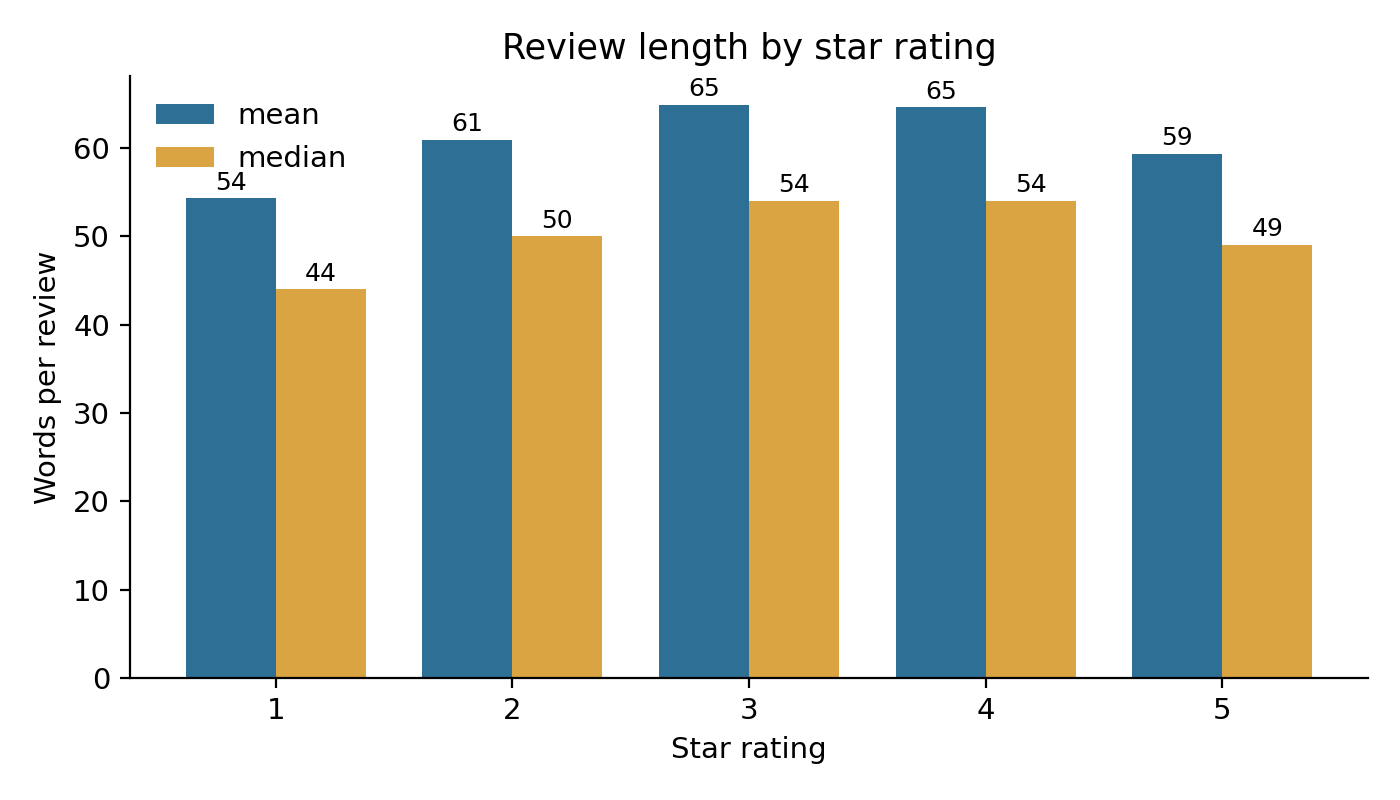

In [7]:
for f in sorted((W2/'figures').glob('w2_fig0[1-6]*.png')): display(Image(filename=str(f), width=620))

## 4. NLP pilot summary (weak labels from star ratings; feasibility only)

In [8]:
rows = [(k, NLP[k]['accuracy'], NLP[k]['macro_f1']) for k in ['baseline_majority','vader','tfidf_nb','tfidf_logreg']]
display(pd.DataFrame(rows, columns=['method','accuracy','macro_F1']).round(3))
print('sample:', NLP['sample_n'], '| reviewers in both train and test:', NLP['author_overlap_train_test'], '| 3-fold CV macro-F1:', round(NLP['logreg_cv_macro_f1']['mean'],3), '+/-', round(NLP['logreg_cv_macro_f1']['sd'],3))

,method,accuracy,macro_F1
0,baseline_majority,0.818,0.300
1,vader,0.812,0.452
2,tfidf_nb,0.889,0.649
3,tfidf_logreg,0.876,0.706


sample: 99867 | reviewers in both train and test: 0 | 3-fold CV macro-F1: 0.704 +/- 0.002


## 5. Consistency check: live numbers versus the report

In [9]:
assert N == I['N'] == 1094411
assert df.product_id.nunique() == I['review_products'] == 2351 and df.brand_name.nunique() == 142
assert int(nn.sum()) == I['validity']['author_id_non_numeric_rows'] == 64
assert int(df.is_recommended.isna().sum()) == I['rec_counts']['missing'] == 167988
assert float(t.loc[2008:2016,'recommendation_missing_pct'].min()) == 100.0
assert round(100*(~has).mean(), 2) == I['validity']['share_reviews_zero_feedback_pct']
assert round(100*chk.files_reviews.sum()/chk.listed_reviews.sum(), 2) == I['count_check']['share_files_of_listed_pct']
print('All live checks agree with the Week 2 report.')

All live checks agree with the Week 2 report.
